PCA

Task 1: Exploratory Data Analysis (EDA):        
1.	Load the dataset and perform basic data exploration.        
2.	Examine the distribution of features using histograms, box plots, or density plots.     
3.	Investigate correlations between features to understand relationships within the data.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('wine.csv')

In [3]:
df.head()

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Type             178 non-null    int64  
 1   Alcohol          178 non-null    float64
 2   Malic            178 non-null    float64
 3   Ash              178 non-null    float64
 4   Alcalinity       178 non-null    float64
 5   Magnesium        178 non-null    int64  
 6   Phenols          178 non-null    float64
 7   Flavanoids       178 non-null    float64
 8   Nonflavanoids    178 non-null    float64
 9   Proanthocyanins  178 non-null    float64
 10  Color            178 non-null    float64
 11  Hue              178 non-null    float64
 12  Dilution         178 non-null    float64
 13  Proline          178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum()

Type               0
Alcohol            0
Malic              0
Ash                0
Alcalinity         0
Magnesium          0
Phenols            0
Flavanoids         0
Nonflavanoids      0
Proanthocyanins    0
Color              0
Hue                0
Dilution           0
Proline            0
dtype: int64

In [7]:
df.columns

Index(['Type', 'Alcohol', 'Malic', 'Ash', 'Alcalinity', 'Magnesium', 'Phenols',
       'Flavanoids', 'Nonflavanoids', 'Proanthocyanins', 'Color', 'Hue',
       'Dilution', 'Proline'],
      dtype='str')

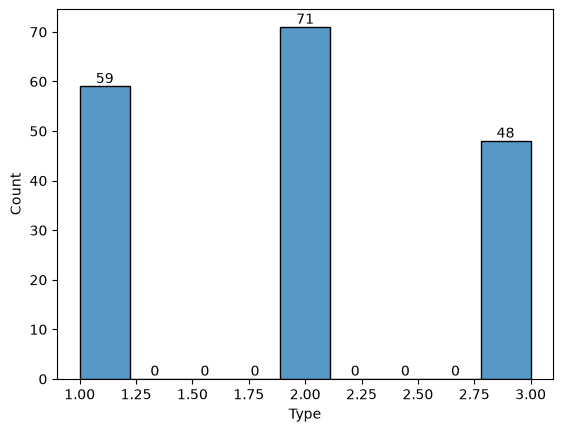

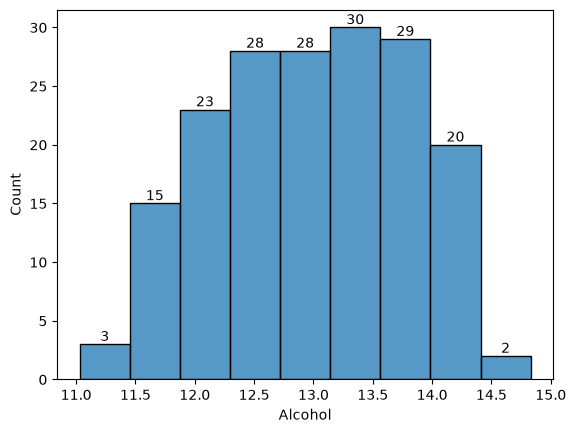

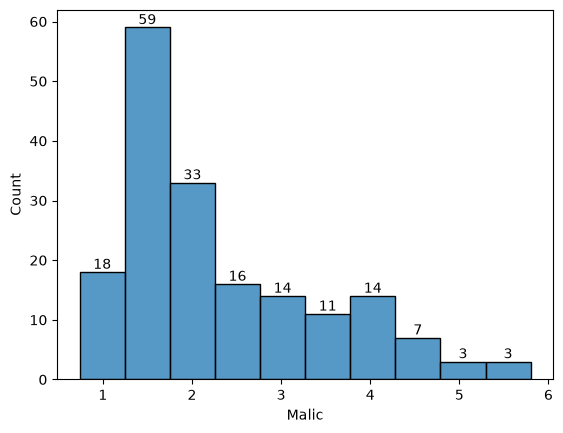

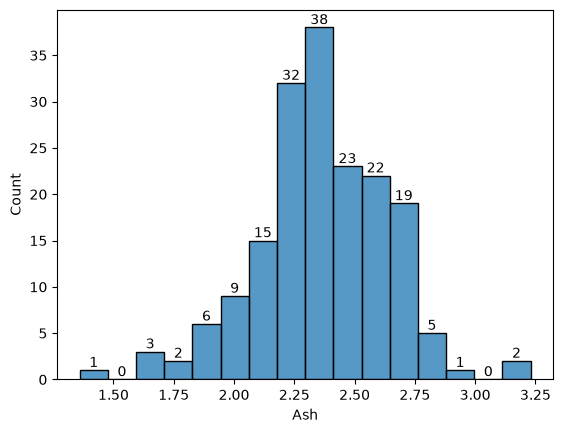

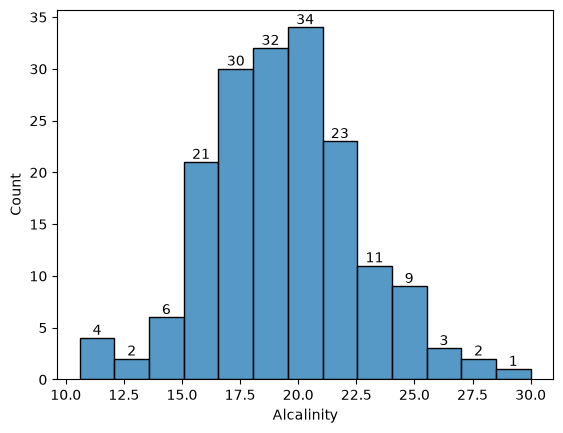

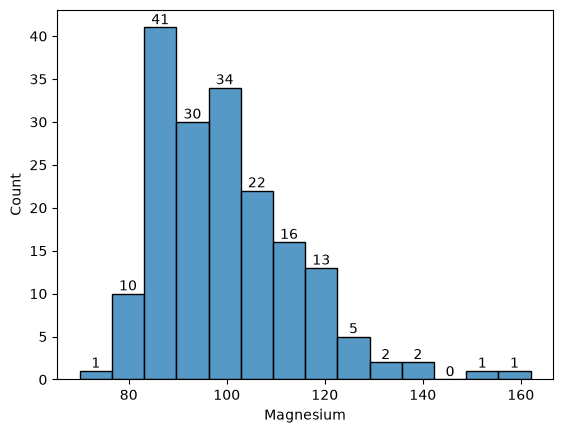

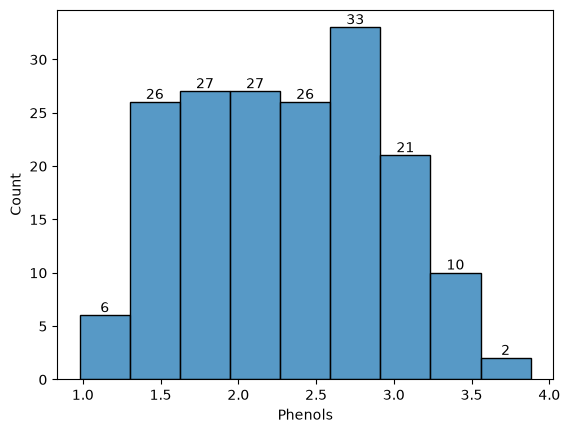

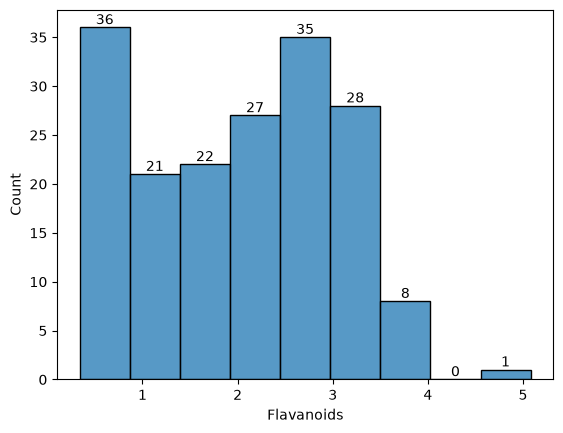

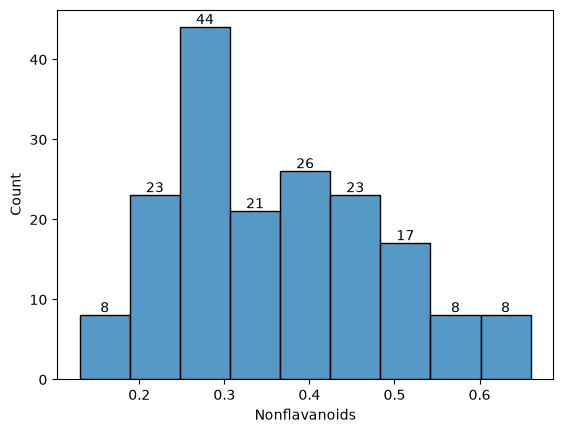

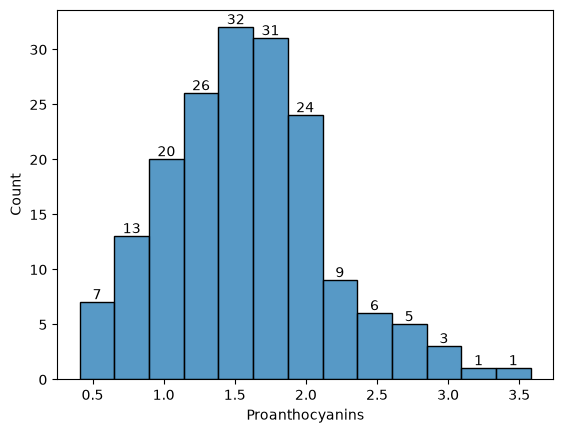

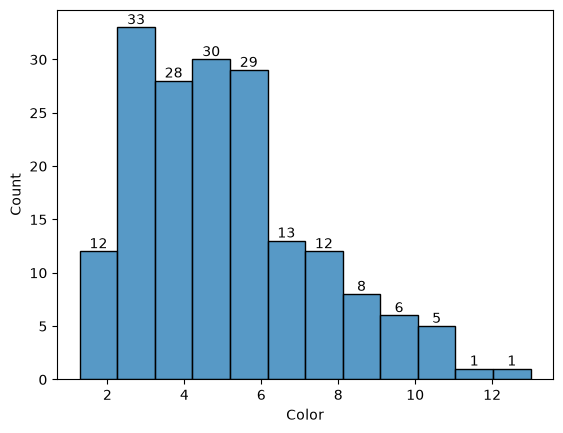

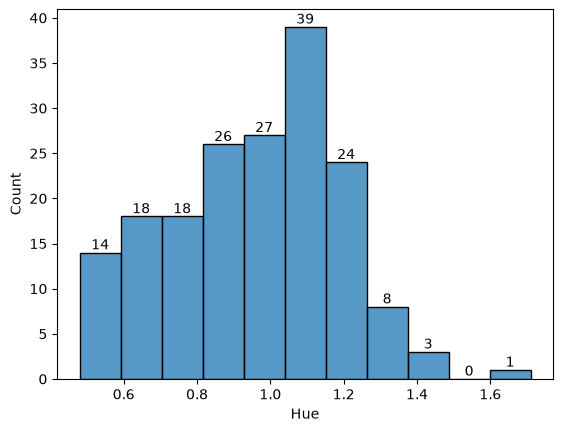

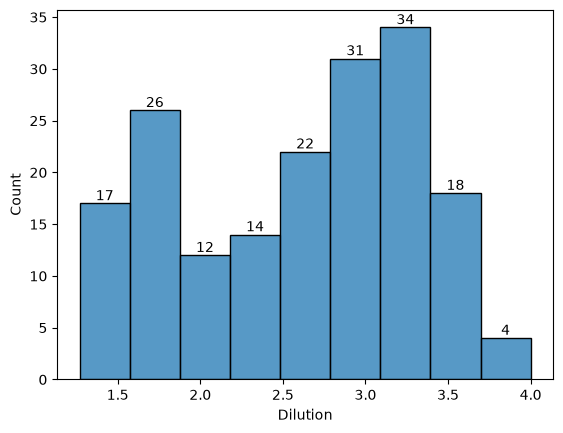

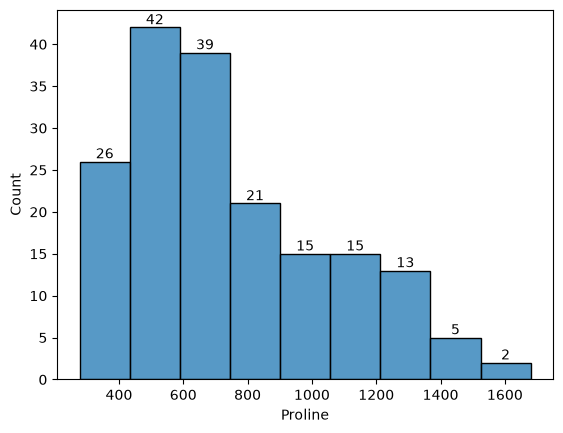

In [8]:
for i in df.columns:
    ax=sns.histplot(df[i])
    ax.bar_label(ax.containers[0])
    plt.show()

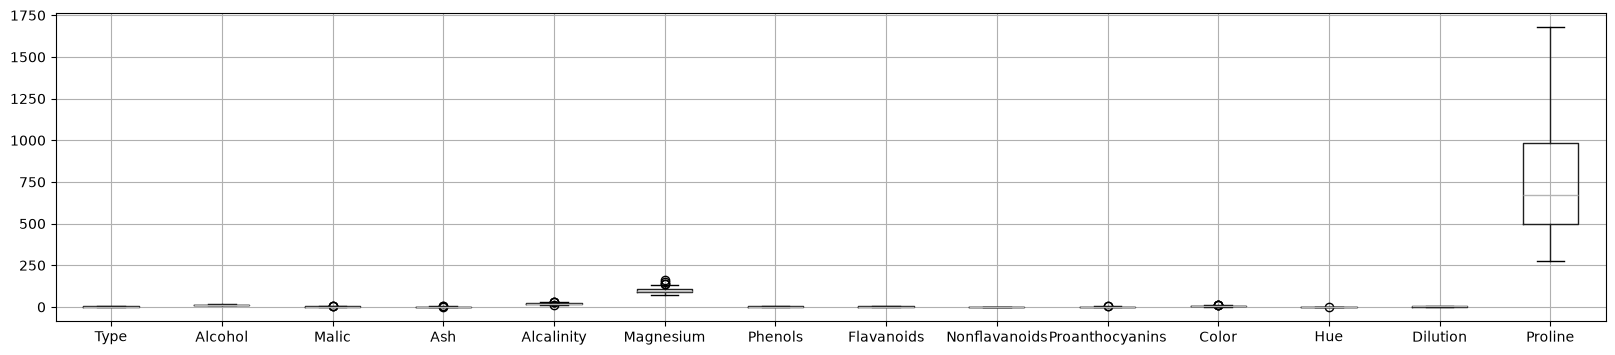

In [9]:
plt.figure(figsize=(20,4))
df.boxplot()
plt.show()

In [10]:
#### outlier capping
first_col=df.columns[0]
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    upper_extreme= Q3+1.5*IQR
    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(include=['int','float']).columns:
    #skips the first_column because it is the targert
    if col==first_col:
        continue
    outlier_capping(df,col)

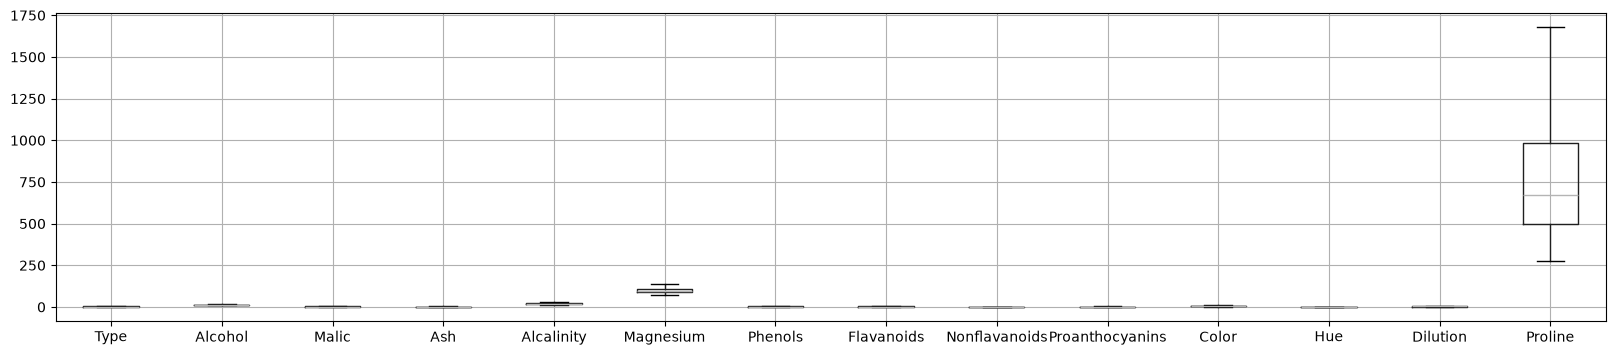

In [11]:
plt.figure(figsize=(20,4))
df.boxplot()
plt.show()

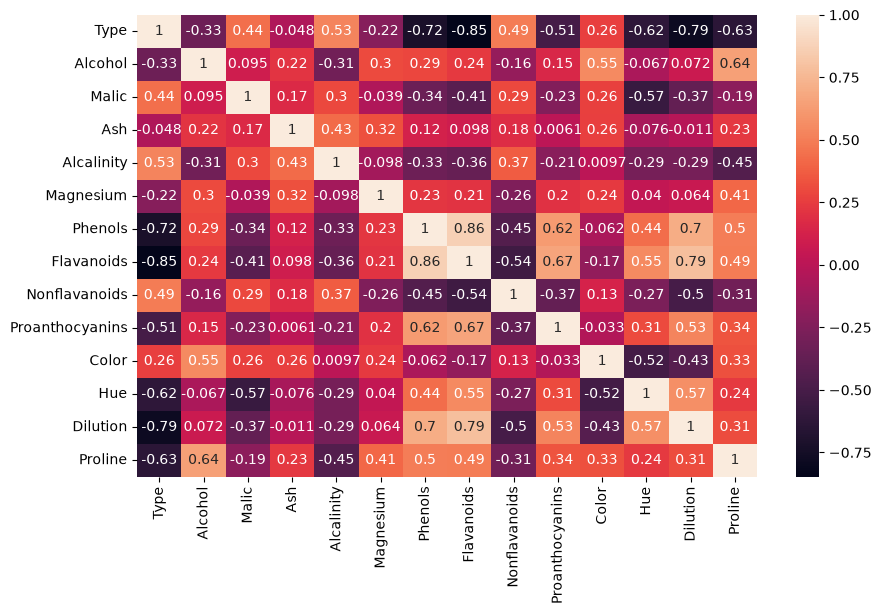

In [12]:
cor=df.corr()
plt.figure(figsize=(10,6))
sns.heatmap(cor,annot=True)
plt.show()

Task 2: Dimensionality Reduction with PCA:      
1.	Standardize the features to ensure they have a mean of 0 and a standard deviation of Implement PCA to reduce the dimensionality of the dataset.     
2.	Determine the optimal number of principal components using techniques like scree plot or cumulative explained variance.     
3.	Transform the original dataset into the principal components.


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

In [14]:
target=df['Type']
features=df.drop(columns=['Type'])

In [15]:
from sklearn.linear_model import Ridge

In [16]:
std_sca=StandardScaler()

In [17]:
features_scaled=std_sca.fit_transform(features)

In [18]:
pca=PCA()
pca.fit(features)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

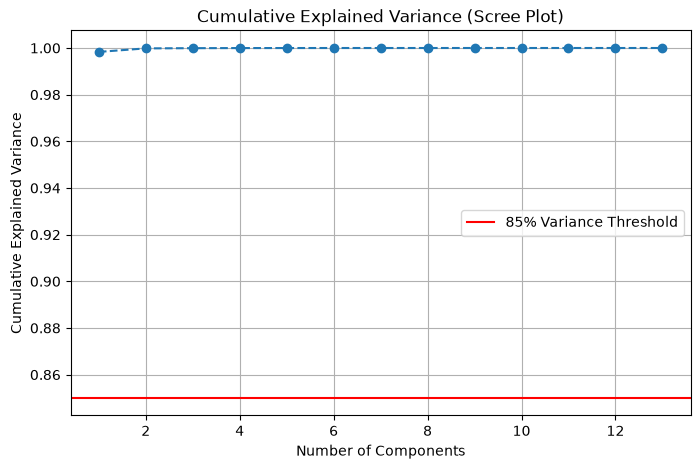

In [19]:
cumulative_variance=np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8,5))
plt.plot(range(1,len(cumulative_variance)+1),cumulative_variance,marker='o',linestyle='--')
plt.axhline(y=0.85,color='r',linestyle='-',label='85% Variance Threshold')
plt.title('Cumulative Explained Variance (Scree Plot)')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

In [20]:
pca_optimal=PCA(n_components=6)
features_pca=pca_optimal.fit_transform(features_scaled)

In [21]:
print(f"Original feature shape: {features_scaled.shape}")
print(f"PCA transformed shape: {features_pca.shape}")

Original feature shape: (178, 13)
PCA transformed shape: (178, 6)


Task 3: Clustering with Original Data:      
1.	Apply a clustering algorithm (e.g., K-means) to the original dataset.       
2.	Visualize the clustering results using appropriate plots.       
3.	Evaluate the clustering performance using metrics such as silhouette score or Davies–Bouldin index.


In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score,davies_bouldin_score

In [23]:
kmean_orig=KMeans(n_clusters=3,random_state=42,n_init=10)
clusters_orig=kmean_orig.fit_predict(features_scaled)

In [24]:
sil_score_orig=silhouette_score(features_scaled,clusters_orig)
db_index_orig=davies_bouldin_score(features_scaled,clusters_orig)

In [25]:
print(f"Original Data Silhouette Score: {sil_score_orig:.4f}")
print(f"Original Data Davies-Bouldin Index: {db_index_orig:.4f}")

Original Data Silhouette Score: 0.2855
Original Data Davies-Bouldin Index: 1.3816


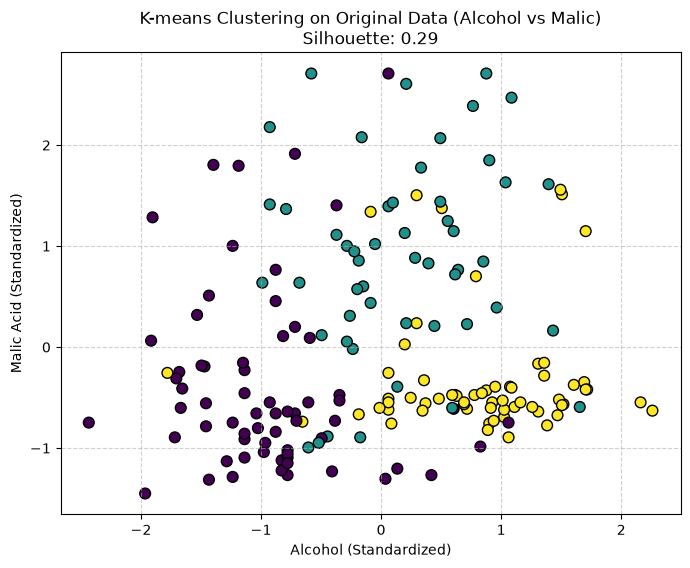

In [26]:
plt.figure(figsize=(8,6))
plt.scatter(features_scaled[:,0],features_scaled[:,1],c=clusters_orig,cmap='viridis',edgecolor='k',s=60)
plt.title(f'K-means Clustering on Original Data (Alcohol vs Malic)\nSilhouette: {sil_score_orig:.2f}')
plt.xlabel('Alcohol (Standardized)')
plt.ylabel('Malic Acid (Standardized)')
plt.grid(True, linestyle='--',alpha=0.6)
plt.show()

Task 4: Clustering with PCA Data:       
1.	Apply the same clustering algorithm to the PCA-transformed dataset.     
2.	Visualize the clustering results obtained from PCA-transformed data.        
3.	Compare the clustering results from PCA-transformed data with those from the original dataset.


In [27]:
kmeans_pca=KMeans(n_clusters=3,random_state=42,n_init=10)
clusters_pca=kmeans_pca.fit_predict(features_pca)

In [28]:
sil_score_pca=silhouette_score(features_pca, clusters_pca)
db_index_pca=davies_bouldin_score(features_pca, clusters_pca)

In [29]:
print(f"PCA Data Silhouette Score: {sil_score_pca:.4f}")
print(f"PCA Data Davies-Bouldin Index: {db_index_pca:.4f}")

PCA Data Silhouette Score: 0.3457
PCA Data Davies-Bouldin Index: 1.1510


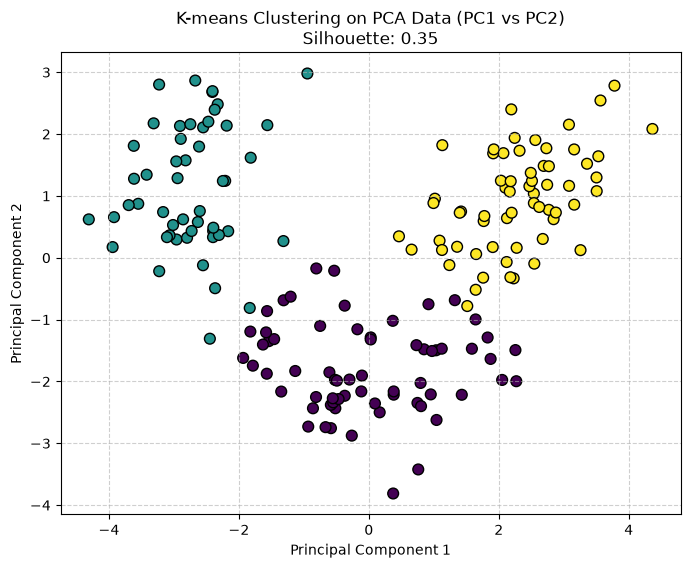

In [30]:
plt.figure(figsize=(8,6))
plt.scatter(features_pca[:,0],features_pca[:,1],c=clusters_pca,cmap='viridis',edgecolor='k',s=60)
plt.title(f'K-means Clustering on PCA Data (PC1 vs PC2)\nSilhouette: {sil_score_pca:.2f}')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True,linestyle='--',alpha=0.6)
plt.show()

Task 5: Comparison and Analysis:        
1.	Compare the clustering results obtained from the original dataset and PCA-transformed data.     
2.	Discuss any similarities or differences observed in the clustering results.     
3.	Reflect on the impact of dimensionality reduction on clustering performance.        
4.	Analyze the trade-offs between using PCA and clustering directly on the original dataset.


In [31]:
print("""" 

Both methods successfully grouped the wines into three main categories, but the PCA method performed 
much better. With PCA, the groupings were tighter and easier to tell apart, scoring a 0.35 Silhouette Score 
compared to the original data's 0.28. This improvement happened because PCA cleaned up the messy, overlapping 
data, making it easier for the algorithm to group similar wines together. The only downside to using PCA is 
that the results are harder to explain. Instead of grouping the wines by recognizable traits like "Alcohol" or "Ash," 
PCA groups them using abstract math, making it harder to describe exactly what makes each wine cluster unique.

""")

" 

Both methods successfully grouped the wines into three main categories, but the PCA method performed 
much better. With PCA, the groupings were tighter and easier to tell apart, scoring a 0.35 Silhouette Score 
compared to the original data's 0.28. This improvement happened because PCA cleaned up the messy, overlapping 
data, making it easier for the algorithm to group similar wines together. The only downside to using PCA is 
that the results are harder to explain. Instead of grouping the wines by recognizable traits like "Alcohol" or "Ash," 
PCA groups them using abstract math, making it harder to describe exactly what makes each wine cluster unique.




Task 6: Conclusion and Insights     
1.	Summarize the key findings and insights from the assignment.        
2.	Discuss the practical implications of using PCA and clustering in data analysis.        
3.	Provide recommendations for when to use each technique based on the analysis conducted.


In [32]:
print("""  

Combining PCA with K-means clustering creates much better and more distinct wine groupings than 
using K-means alone because PCA cleans up messy, overlapping data. In practical data analysis, 
while clustering is a great tool for finding hidden patterns, adding PCA makes the process much 
more efficient by compressing complex variables into a few essential components. As a general 
recommendation, you should cluster directly on the original data when you need to clearly explain 
your results using real-world traits, like specific chemical levels, but you should use PCA first 
when your main goal is getting the sharpest, most accurate groupings from highly correlated datasets.

""")

  

Combining PCA with K-means clustering creates much better and more distinct wine groupings than 
using K-means alone because PCA cleans up messy, overlapping data. In practical data analysis, 
while clustering is a great tool for finding hidden patterns, adding PCA makes the process much 
more efficient by compressing complex variables into a few essential components. As a general 
recommendation, you should cluster directly on the original data when you need to clearly explain 
your results using real-world traits, like specific chemical levels, but you should use PCA first 
when your main goal is getting the sharpest, most accurate groupings from highly correlated datasets.


